# C5 — XGBoost: Tuning + Accuracy/Threshold Analysis

This is still **C5**.

## Important distinction

We should NOT force Optuna to maximize raw accuracy just because the target is imbalanced
(~23% positive). A classifier can obtain high accuracy by predicting mostly failures.

Therefore:

**Model hyperparameters:** optimized using 5-fold case-grouped CV and **PR-AUC**.

**Deployment threshold:** selected separately on the validation set, where we examine:
- accuracy
- precision
- recall
- F1
- confusion matrix

This lets us answer the user's 90%+ accuracy requirement without corrupting the
probability/ranking model objective.

The test set is not used to choose the threshold.


In [1]:

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data" / "c4_splits").exists():
    ROOT = ROOT.parent

SPLIT_DIR = ROOT / "data" / "c4_splits"
REPORT_DIR = ROOT / "reports" / "c5_xgboost_accuracy"
MODEL_DIR = ROOT / "models" / "c5"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20260824
TARGET = "y"
GROUP_COL = "case_id"
N_SPLITS = 5
N_TRIALS = 50

train = pd.read_csv(
    SPLIT_DIR / "train.csv",
    low_memory=False,
)
valid = pd.read_csv(
    SPLIT_DIR / "validation.csv",
    low_memory=False,
)
test = pd.read_csv(
    SPLIT_DIR / "test.csv",
    low_memory=False,
)

print("Train:", train.shape)
print("Validation:", valid.shape)
print("Test:", test.shape)
print("Train positive rate:", train[TARGET].mean())


Train: (110385, 37)
Validation: (23471, 37)
Test: (23567, 37)
Train positive rate: 0.2282194138696381


## 1. Feature Contract

In [2]:

ID_COLUMNS = {
    "customer_id",
    "subscription_id",
    "case_id",
}

POLICY_COLUMNS = {
    "logging_policy",
}

INTERVENTION_COLUMNS = {
    "action_type",
    "channel",
}

EXCLUDED = ID_COLUMNS | POLICY_COLUMNS | {TARGET}

FEATURES = [
    c for c in train.columns
    if c not in EXCLUDED
]

CATEGORICAL_COLS = [
    c for c in FEATURES
    if (
        c in INTERVENTION_COLUMNS
        or not pd.api.types.is_numeric_dtype(train[c])
    )
]

NUMERIC_COLS = [
    c for c in FEATURES
    if (
        c not in CATEGORICAL_COLS
        and pd.api.types.is_numeric_dtype(train[c])
    )
]

print("Total model inputs:", len(FEATURES))
print("Numeric:", len(NUMERIC_COLS))
print("Categorical:", len(CATEGORICAL_COLS))
print("Intervention variables:",
      [c for c in INTERVENTION_COLUMNS if c in train.columns])


Total model inputs: 32
Numeric: 20
Categorical: 12
Intervention variables: ['channel', 'action_type']


## 2. Preprocessing

In [3]:

def make_preprocessor():
    numeric_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ])

    categorical_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2,
            ),
        ),
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipe,
            NUMERIC_COLS,
        ),
        (
            "categorical",
            categorical_pipe,
            CATEGORICAL_COLS,
        ),
    ])


## 3. Probability Metrics

In [4]:

def probability_metrics(y_true, proba):
    proba = np.clip(
        np.asarray(proba, dtype=float),
        1e-7,
        1 - 1e-7,
    )
    y_true = np.asarray(y_true)

    return {
        "pr_auc": float(
            average_precision_score(
                y_true,
                proba,
            )
        ),
        "roc_auc": float(
            roc_auc_score(
                y_true,
                proba,
            )
        ),
        "log_loss": float(
            log_loss(
                y_true,
                proba,
            )
        ),
        "brier": float(
            brier_score_loss(
                y_true,
                proba,
            )
        ),
    }


def threshold_metrics(y_true, proba, threshold):
    y_true = np.asarray(y_true)
    pred = (
        np.asarray(proba) >= threshold
    ).astype(int)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_true,
            pred,
        ),
        "precision": precision_score(
            y_true,
            pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            pred,
            zero_division=0,
        ),
        "predicted_positive_rate": float(
            pred.mean()
        ),
    }


## 4. XGBoost Optuna Search Space

In [5]:

import optuna

def xgb_params(trial):
    return {
        "n_estimators": trial.suggest_int(
            "n_estimators",
            200,
            1000,
            step=50,
        ),
        "max_depth": trial.suggest_int(
            "max_depth",
            3,
            9,
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.15,
            log=True,
        ),
        "min_child_weight": trial.suggest_int(
            "min_child_weight",
            1,
            25,
        ),
        "subsample": trial.suggest_float(
            "subsample",
            0.65,
            1.00,
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.65,
            1.00,
        ),
        "gamma": trial.suggest_float(
            "gamma",
            0.0,
            4.0,
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-5,
            10.0,
            log=True,
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            1e-4,
            30.0,
            log=True,
        ),
    }


## 5. Grouped CV Objective

Optuna uses only the C4 training set.

`case_id` is the grouping variable, so the same recovery case cannot occur
on both sides of a CV fold.

**Primary tuning objective = mean CV PR-AUC.**


In [6]:

cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED,
)

X_train = train[FEATURES]
y_train = train[TARGET].astype(int)
groups = train[GROUP_COL]


def xgb_objective(trial):
    params = xgb_params(trial)
    fold_scores = []

    for fold, (tr_idx, va_idx) in enumerate(
        cv.split(
            X_train,
            y_train,
            groups,
        )
    ):
        X_tr = X_train.iloc[tr_idx]
        X_va = X_train.iloc[va_idx]
        y_tr = y_train.iloc[tr_idx]
        y_va = y_train.iloc[va_idx]

        prep = make_preprocessor()

        X_tr_enc = prep.fit_transform(X_tr)
        X_va_enc = prep.transform(X_va)

        model = XGBClassifier(
            **params,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=SEED + fold,
            n_jobs=-1,
        )

        model.fit(
            X_tr_enc,
            y_tr,
        )

        proba = model.predict_proba(
            X_va_enc
        )[:, 1]

        score = average_precision_score(
            y_va,
            proba,
        )

        fold_scores.append(score)

        trial.report(
            float(np.mean(fold_scores)),
            step=fold,
        )

        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr(
        "cv_pr_auc_std",
        float(np.std(fold_scores)),
    )

    return float(
        np.mean(fold_scores)
    )


## 6. Run Optuna

In [7]:

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

xgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=SEED,
    ),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=8,
        n_warmup_steps=2,
    ),
)

xgb_study.optimize(
    xgb_objective,
    n_trials=N_TRIALS,
    show_progress_bar=True,
)

print(
    "Best CV PR-AUC:",
    xgb_study.best_value,
)

print(
    "Best parameters:"
)

print(
    xgb_study.best_params
)


  0%|          | 0/50 [00:00<?, ?it/s]

Best CV PR-AUC: 0.8111897351655477
Best parameters:
{'n_estimators': 750, 'max_depth': 9, 'learning_rate': 0.021282443665857322, 'min_child_weight': 1, 'subsample': 0.9088249503896849, 'colsample_bytree': 0.665998401220248, 'gamma': 1.6973264832524302, 'reg_alpha': 1.4204811707801293e-05, 'reg_lambda': 23.009912471175372}


## 7. Fit Best XGBoost on Complete C4 TRAIN

In [8]:

from xgboost import XGBClassifier

best_xgb = XGBClassifier(
    **xgb_study.best_params,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=SEED,
    n_jobs=-1,
)

final_prep = make_preprocessor()

Xtr = final_prep.fit_transform(
    train[FEATURES]
)

Xva = final_prep.transform(
    valid[FEATURES]
)

Xte = final_prep.transform(
    test[FEATURES]
)

print("Encoded shapes:")
print("Train:", Xtr.shape)
print("Validation:", Xva.shape)
print("Test:", Xte.shape)

best_xgb.fit(
    Xtr,
    train[TARGET].astype(int),
)

train_proba = best_xgb.predict_proba(
    Xtr
)[:, 1]

valid_proba = best_xgb.predict_proba(
    Xva
)[:, 1]

test_proba = best_xgb.predict_proba(
    Xte
)[:, 1]

probability_results = pd.DataFrame([
    {
        "split": "train",
        **probability_metrics(
            train[TARGET],
            train_proba,
        ),
    },
    {
        "split": "validation",
        **probability_metrics(
            valid[TARGET],
            valid_proba,
        ),
    },
    {
        "split": "test",
        **probability_metrics(
            test[TARGET],
            test_proba,
        ),
    },
])

display(probability_results)


Encoded shapes:
Train: (110385, 79)
Validation: (23471, 79)
Test: (23567, 79)


,split,pr_auc,roc_auc,log_loss,brier
0,train,0.891424,0.961588,0.218343,0.066106
1,validation,0.811060,0.934174,0.266406,0.083262
2,test,0.829775,0.939201,0.254480,0.078561


## 8. Accuracy Is a Threshold Question

XGBoost produces probabilities, not final 0/1 decisions.

For example:

`0.51`, `0.73`, `0.12`, ...

Calling `>= 0.5` a positive case is only one possible threshold.

Therefore, if we care about classification accuracy, we should choose the
threshold on **VALIDATION**, not on TEST.

The next cell searches thresholds from 0.05 to 0.95.

In [9]:

threshold_grid = np.arange(
    0.05,
    0.951,
    0.005,
)

threshold_rows = [
    threshold_metrics(
        valid[TARGET],
        valid_proba,
        float(t),
    )
    for t in threshold_grid
]

threshold_results = pd.DataFrame(
    threshold_rows
)

display(
    threshold_results.sort_values(
        "accuracy",
        ascending=False,
    ).head(20)
)

best_accuracy_row = (
    threshold_results
    .sort_values(
        "accuracy",
        ascending=False,
    )
    .iloc[0]
)

best_accuracy_threshold = float(
    best_accuracy_row["threshold"]
)

print(
    f"Best validation accuracy threshold: "
    f"{best_accuracy_threshold:.3f}"
)

print(
    f"Validation accuracy: "
    f"{best_accuracy_row['accuracy']:.4f}"
)

print(
    f"Validation precision: "
    f"{best_accuracy_row['precision']:.4f}"
)

print(
    f"Validation recall: "
    f"{best_accuracy_row['recall']:.4f}"
)

print(
    f"Validation F1: "
    f"{best_accuracy_row['f1']:.4f}"
)


,threshold,accuracy,precision,recall,f1,predicted_positive_rate
83,0.465,0.885689,0.804944,0.663702,0.727531,0.189596
86,0.480,0.885604,0.814034,0.651288,0.723623,0.183972
90,0.500,0.885476,0.825366,0.636650,0.718828,0.177368
89,0.495,0.885433,0.822228,0.640170,0.719867,0.179029
85,0.475,0.885390,0.810650,0.654438,0.724216,0.185633
91,0.505,0.885348,0.827603,0.633315,0.717540,0.175962
87,0.485,0.885348,0.816713,0.646470,0.721688,0.182012
79,0.445,0.885348,0.794003,0.677043,0.730873,0.196072
95,0.525,0.885348,0.839098,0.620345,0.713327,0.169997
93,0.515,0.885305,0.831902,0.628127,0.715794,0.173619


Best validation accuracy threshold: 0.465
Validation accuracy: 0.8857
Validation precision: 0.8049
Validation recall: 0.6637
Validation F1: 0.7275


## 9. Accuracy vs Precision/Recall Trade-off

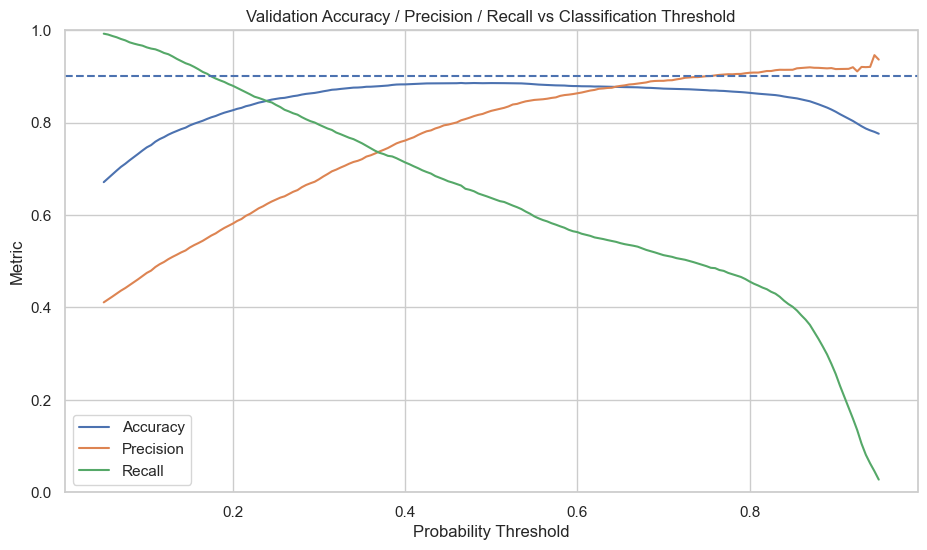

In [10]:

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=threshold_results,
    x="threshold",
    y="accuracy",
    label="Accuracy",
)

sns.lineplot(
    data=threshold_results,
    x="threshold",
    y="precision",
    label="Precision",
)

sns.lineplot(
    data=threshold_results,
    x="threshold",
    y="recall",
    label="Recall",
)

plt.axhline(
    0.90,
    linestyle="--",
    label="90% accuracy target",
)

plt.ylim(0, 1)

plt.title(
    "Validation Accuracy / Precision / Recall "
    "vs Classification Threshold"
)

plt.ylabel("Metric")
plt.xlabel("Probability Threshold")

plt.show()


## 10. Important 90% Accuracy Check

A 90% accuracy score is NOT automatically evidence of a better recovery model.

Because the dataset has ~23% positives, increasing the threshold can make the
model predict more cases as failures and increase raw accuracy while reducing
recall of successful interventions.

Therefore report **accuracy together with precision, recall and F1**.

If a threshold reaches 90% accuracy but recall collapses, we should NOT treat
that as a successful model improvement.

In [11]:

# Evaluate the selected validation threshold on validation AND test.
# The threshold was chosen using VALIDATION only.

validation_threshold_metrics = threshold_metrics(
    valid[TARGET],
    valid_proba,
    best_accuracy_threshold,
)

test_threshold_metrics = threshold_metrics(
    test[TARGET],
    test_proba,
    best_accuracy_threshold,
)

threshold_comparison = pd.DataFrame([
    {
        "split": "validation",
        **validation_threshold_metrics,
    },
    {
        "split": "test",
        **test_threshold_metrics,
    },
])

display(
    threshold_comparison
)

if (
    validation_threshold_metrics["accuracy"] >= 0.90
    and test_threshold_metrics["accuracy"] >= 0.90
):
    print(
        "90%+ accuracy achieved on both validation and test "
        "at the validation-selected threshold."
    )
else:
    print(
        "90%+ accuracy was NOT achieved on both validation and test "
        "at the validation-selected threshold."
    )

print(
    "\nDo not change the threshold using the test set."
)


,split,threshold,accuracy,precision,recall,f1,predicted_positive_rate
0,validation,0.465,0.885689,0.804944,0.663702,0.727531,0.189596
1,test,0.465,0.889804,0.802395,0.679564,0.735889,0.191327


90%+ accuracy was NOT achieved on both validation and test at the validation-selected threshold.

Do not change the threshold using the test set.


## 11. Compare with C5 Fixed Baselines

In [12]:

baseline_path = (
    ROOT
    / "reports"
    / "c5_baseline"
    / "baseline_metrics.csv"
)

if baseline_path.exists():

    baseline = pd.read_csv(
        baseline_path
    )

    display(
        baseline[
            [
                "model",
                "split",
                "pr_auc",
                "roc_auc",
                "log_loss",
                "brier",
            ]
        ]
        .sort_values(
            ["split", "pr_auc"],
            ascending=[True, False],
        )
    )

else:
    print(
        "Baseline report not found:",
        baseline_path,
    )


,model,split,pr_auc,roc_auc,log_loss,brier
5,gradient_boosting,test,0.787352,0.914982,0.300595,0.090900
3,logistic_regression,test,0.723009,0.881096,0.341749,0.104604
1,base_rate,test,0.225909,0.500000,0.534301,0.174880
4,gradient_boosting,validation,0.774632,0.910991,0.310199,0.094811
2,logistic_regression,validation,0.710845,0.872573,0.353747,0.109135
0,base_rate,validation,0.229943,0.500000,0.539216,0.177072


## 12. Save C5 XGBoost Results

In [13]:

import joblib
import json

probability_results.to_csv(
    REPORT_DIR / "xgboost_probability_metrics.csv",
    index=False,
)

threshold_results.to_csv(
    REPORT_DIR / "xgboost_validation_thresholds.csv",
    index=False,
)

threshold_comparison.to_csv(
    REPORT_DIR / "xgboost_threshold_final_metrics.csv",
    index=False,
)

xgb_study.trials_dataframe().to_csv(
    REPORT_DIR / "xgboost_optuna_trials.csv",
    index=False,
)

with open(
    REPORT_DIR / "xgboost_best_params.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            "optimization_metric": "pr_auc",
            "cv": "5-fold StratifiedGroupKFold",
            "group": GROUP_COL,
            "best_cv_pr_auc": float(
                xgb_study.best_value
            ),
            "best_params": xgb_study.best_params,
            "selected_validation_threshold": best_accuracy_threshold,
        },
        f,
        indent=2,
    )

final_pipeline = Pipeline([
    (
        "preprocess",
        final_prep,
    ),
    (
        "model",
        best_xgb,
    ),
])

joblib.dump(
    final_pipeline,
    MODEL_DIR / "xgboost_tuned_c5_accuracy_aware.joblib",
)

print(
    "Saved XGBoost C5 artifacts to:",
    REPORT_DIR,
)


Saved XGBoost C5 artifacts to: c:\Users\Soham\Documents\revenue-recovery\reports\c5_xgboost_accuracy
